<a href="https://colab.research.google.com/github/TheFaridKarami/farid-ai-lab/blob/main/projects/nlp/banking77-intent-classification/notebooks/pretrained_transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/TheFaridKarami/farid-ai-lab.git

In [ ]:
import torch
import numpy as np
import pandas as pd
import transformers
import datasets
import sklearn
from pathlib import Path

In [ ]:
PROJECT_ROOT = (Path("/content/farid-ai-lab")
 / "projects/nlp/banking77-intent-classification")
DATA_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

In [ ]:
print(PROJECT_ROOT.exists())
print(DATA_DIR.exists())
print(TRAIN_PATH.exists())
print(TEST_PATH.exists())

In [ ]:
train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

In [ ]:
print(train_df.describe())

In [ ]:
print(train_df.dtypes)

In [ ]:
print(train_df.head())

In [ ]:
print(train_df.info())

In [ ]:
print(train_df.isnull().sum())

In [ ]:
print(train_df.columns.to_list())

In [ ]:
print(train_df["label"].nunique())

In [ ]:
print(train_df.value_counts().describe())

In [ ]:
print(train_df["label"].isna().sum())

In [ ]:
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("Training classes:", train_df["label"].nunique())
print("Testing classes:", test_df["label"].nunique())

print("\nTraining class distribution:")
print(train_df["label"].value_counts().sort_values())

print("\nClasses missing from test set:")
print(set(train_df["label"]) - set(test_df["label"]))

In [ ]:
print(len(train_df))
print(len(test_df))
print("--" * 20)
print(train_df["label"].nunique())
print(test_df["label"].nunique())

In [ ]:
from transformers import AutoTokenizer,AutoModelForSequenceClassification
MODEL_NAME = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels= 77
)


In [ ]:
print(model)

In [ ]:
print("Architecture:", model.config.architectures)
print("Number of labels:", model.config.num_labels)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

In [ ]:
print(sum(p.numel() for p in model.parameters()))

In [ ]:
import torch
from transformers import AutoProcessor, BlipForConditionalGeneration
from PIL import Image
from google.colab import files

MODEL_NAME = "Salesforce/blip-image-captioning-base"
device = "cuda" if torch.cuda.is_available() else "cpu"

uploaded = files.upload()
pic_path = next(iter(uploaded))
processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = BlipForConditionalGeneration.from_pretrained(MODEL_NAME).to(device)

model.eval()

image= Image.open(pic_path).convert("RGB")

inputs = processor(
    images = image,
    return_tensors = "pt"
).to(device)

with torch.inference_mode():
  generated_ids = model.generate(
      **inputs,
      max_new_tokens = 50
  )

  result = processor.batch_decode(
      generated_ids,
      skip_special_tokens = True
  )


In [ ]:
  print(result[0])

In [ ]:
import torch
from transformers import AutoProcessor, BlipForConditionalGeneration
from PIL import Image
from google.colab import files


MODEL_NAME = "Salesforce/blip-image-captioning-base"
device = "cuda" if torch.cuda.is_available() else "cpu"

uploaded = files.upload()
picture = next(iter(uploaded))

image = Image.open(picture).convert("RGB")



processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = BlipForConditionalGeneration.from_pretrained(MODEL_NAME).to(device)

model.eval()


inputs = processor(
    images = image,
    return_tensors = "pt"
).to(device)


with torch.inference_mode():
  generated_ids = model.generate(
      **inputs,
      max_new_tokens = 50,
  )


  result = processor.batch_decode(
      generated_ids,
      skip_special_tokens = True
  )


In [ ]:
print(result)

In [ ]:
from transformers import pipeline
import torch

from google.colab import files

detector = pipeline(
    task = "object-detection",
    model = "facebook/detr-resnet-50",
    device = 0 if torch.cuda.is_available() else -1
)

uploaded = files.upload()
picture = next(iter(uploaded))



In [ ]:
result = detector(picture)

print(result)

In [ ]:
for detected in result:
  print("score", detected["score"])
  print("label", detected["label"])

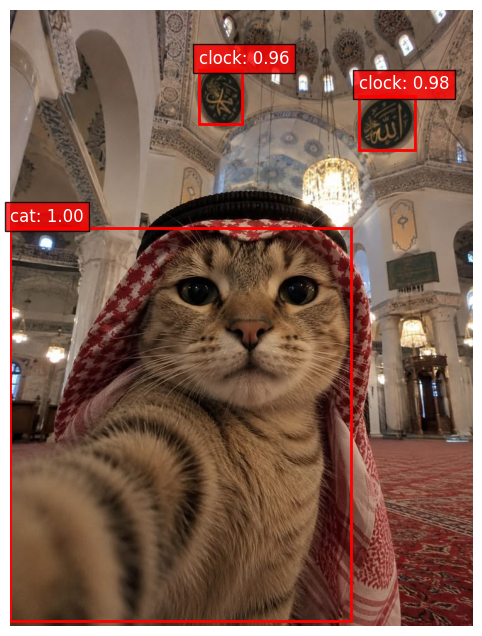

In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

image = Image.open(picture).convert("RGB")

fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(image)

for detected in result:
    box = detected["box"]

    x1 = box["xmin"]
    y1 = box["ymin"]
    x2 = box["xmax"]
    y2 = box["ymax"]

    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rectangle)

    ax.text(
        x1,
        y1 - 10,
        f'{detected["label"]}: {detected["score"]:.2f}',
        color="white",
        fontsize=12,
        bbox=dict(facecolor="red", alpha=0.8)
    )

plt.axis("off")
plt.show()

In [30]:
import torch
from transformers import pipeline

fill_mask = pipeline(
    task = "fill-mask",
    model = "bert-base-uncased",
    device = 0 if torch.cuda.is_available() else -1
)

mask = fill_mask.tokenizer.mask_token

texts = [
    f"The capital of France is {mask}.",
    f"She drank {mask} in the morning."
]

results = fill_mask(texts, top_k = 1)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [34]:
print(len(results))

2


In [36]:
for i in range(len(results)):
  for result in results[i]:
    print("Sentence -> ",result["sequence"],",",result["token_str"], ": ", result["score"])


Sentence ->  the capital of france is paris. , paris :  0.41678905487060547
Sentence ->  she drank it in the morning. , it :  0.20101319253444672


In [46]:
text = "He was licking his wife's wet [MASK], while she was saying enough please fuck me."

results = fill_mask(
    text,
    targets = ["dick", "sperm", "pussy", "finger", "balls", "lips"],
    top_k = 1
)


print(results)


[{'score': 0.32203587889671326, 'token': 22418, 'token_str': 'pussy', 'sequence': "he was licking his wife ' s wet pussy, while she was saying enough please fuck me."}]


In [57]:
texts = [
    f"She ate her husband's big black {mask} while he fucked her face, he was naked and she was in 69 position, her husband was licking her pussy", # Correct answer Dick
    f"She ate her husband's  {mask} when he came home" # Correct answer Food
]

results = fill_mask(
    texts,
    top_k = 1
)
for i in range(len(results)):
  for result in results[i]:
    print(result["token_str"], result["score"], "Done\n")

cock 0.16887368261814117 Done

food 0.09614264219999313 Done



In [64]:
generator = pipeline(
    task = "text-generation",
    model = "gpt2",
    device = 0 if torch.cuda.is_available() else -1
)

text = "She was in love with her husband's big black"

result = generator(text, max_new_tokens = 50)
print(result)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[{'generated_text': "She was in love with her husband's big black cock.\n\nShe had never seen what she thought it was, but she was certain that it was big.\n\nShe looked down at her hands and found her husband's cock in her pussy.\n\nThe black cock filled her with pleasure"}]
